# Reliable Calibration

This notebook calibrates the HYMOD rainfall-runoff model for USGS gage 01666500 with 20 years of
daily data and uses that calibration to show what `sceua.minimize` guarantees about its results:

1. The reported best point is a point the objective was evaluated at, and `fun` is its value.
2. Changing the units of a parameter leaves the best calibrated NSE unchanged.
3. One-parameter problems and integer starting points work, and starting points outside the
   bounds are rejected.
4. Parameter sets where the model returns NaN are skipped, and a run where every value is NaN
   reports failure.
5. The evaluation budget, `max_evals`, is honored.

Each section ends with `assert` statements on the behavior it shows. The test suite runs the
code of this notebook (`tests/test_examples.py`), so these checks run on every change.

## Model and data

The model is the HYMOD implementation from the [calibration example](calibration.md). The
forcing (precipitation and potential evapotranspiration) and the observed streamflow, all in
mm/day, come from the data file of the test suite.

In [1]:
from pathlib import Path

import numpy as np
import numpy.typing as npt
import pandas as pd
from numba import njit

import sceua

FloatArray = npt.NDArray[np.float32]


@njit(nogil=True)
def _linear_reservoir(
    x_slow: np.float32, inflow: np.float32, k_s: np.float32
) -> tuple[np.float32, np.float32]:
    """Run the linear reservoir model."""
    xn_slow = (1 - k_s) * x_slow + (1 - k_s) * inflow
    outflow = k_s / (1 - k_s) * xn_slow
    return xn_slow, outflow


@njit(nogil=True)
def _excess(
    prcp_t: np.float32,
    pet_t: np.float32,
    x_loss: np.float32,
    c_max: np.float32,
    b_exp: np.float32,
) -> tuple[np.float32, np.float32]:
    """Calculate excess precipitation and evaporation."""
    ct_prev = c_max * (1 - np.power(np.abs(1 - ((b_exp + 1) * (x_loss) / c_max)), 1 / (b_exp + 1)))
    er_1 = np.maximum(prcp_t - c_max + ct_prev, 0)
    s_1 = prcp_t - er_1
    dummy = np.minimum((ct_prev + s_1) / c_max, 1)
    xn = c_max / (b_exp + 1) * (1 - np.power(np.abs(1 - dummy), b_exp + 1))

    er_2 = np.maximum(s_1 - (xn - x_loss), 0)

    evap = (1 - (((c_max / (b_exp + 1)) - xn) / (c_max / (b_exp + 1)))) * pet_t
    xn = np.maximum(xn - evap, 0)

    return er_1 + er_2, xn


@njit(nogil=True)
def _simulate(
    prcp: FloatArray,
    pet: FloatArray,
    c_max: np.float32,
    b_exp: np.float32,
    alpha: np.float32,
    k_s: np.float32,
    k_q: np.float32,
) -> FloatArray:
    """Run HYMOD model."""
    x_loss = np.float32(0.0)
    x_slow = np.float32(0.0)
    outflow = np.float32(0.0)
    x_quick = np.zeros(3, dtype="f4")
    n_steps = prcp.shape[0]
    q_out = np.zeros(n_steps, dtype="f4")

    for t in range(n_steps):
        et, x_loss = _excess(prcp[t], pet[t], x_loss, c_max, b_exp)
        u_q = alpha * et
        u_s = (1 - alpha) * et
        x_slow, q_s = _linear_reservoir(x_slow, u_s, k_s)
        inflow = u_q
        for i in range(3):
            x_quick[i], outflow = _linear_reservoir(x_quick[i], inflow, k_q)
            inflow = outflow
        q_out[t] = q_s + outflow
    return q_out


@njit(nogil=True)
def compute_nse(sim: FloatArray, obs: FloatArray) -> float:
    """Compute Nash-Sutcliffe Efficiency."""
    nse = 1 - np.sum(np.square(obs - sim)) / np.sum(np.square(obs - np.mean(obs)))
    return nse


class HYMOD:
    """Simulate a watershed using HYMOD model."""

    def __init__(self, clm: pd.DataFrame, qobs: pd.Series, warmup_years: int) -> None:
        self.prcp = clm["pr"].to_numpy("f4")
        self.pet = clm["pet"].to_numpy("f4")
        self.qobs = qobs.to_numpy("f4")
        self.cal_idx = np.s_[warmup_years * 365 :]

    def __call__(self, x: FloatArray) -> FloatArray:
        """Simulate the watershed."""
        c_max, b_exp, alpha, k_s, k_q = x.astype("f4")
        return _simulate(self.prcp, self.pet, c_max, b_exp, alpha, k_s, k_q)

    def fit(self, x: FloatArray) -> float:
        """Return the negative NSE over the calibration period, since sceua minimizes."""
        return -compute_nse(self(x)[self.cal_idx], self.qobs[self.cal_idx])

In [2]:
data = pd.read_csv(
    Path("..", "..", "tests", "01666500_hymod.csv"), index_col="time", parse_dates=True
)
model = HYMOD(data[["pr", "pet"]], data["qobs"], warmup_years=1)
bounds = {
    "c_max": (1, 1500),
    "b_exp": (0.0, 1.99),
    "alpha": (0.01, 0.99),
    "k_s": (0.01, 0.14),
    "k_q": (0.14, 0.99),
}
lower, upper = np.array(list(bounds.values())).T
data.describe().round(2)

,pr,pet,qobs
count,7305.00,7305.00,7305.00
mean,3.21,3.18,1.14
std,8.18,1.70,1.89
min,0.00,0.00,0.01
25%,0.00,1.67,0.39
50%,0.00,2.99,0.75
75%,2.09,4.61,1.32
max,110.88,8.22,57.45


## 1. The reported best point was evaluated

`Result.x` is the best point found, `Result.fun` is the objective value at that point, and
`Result.xv` and `Result.funv` hold every evaluated point and its value. Five runs with different
seeds:

In [3]:
runs = {seed: sceua.minimize(model.fit, list(bounds.values()), seed=seed) for seed in range(5)}
summary = (
    pd.DataFrame(
        {
            seed: {**dict(zip(bounds, r.x)), "NSE": -r.fun, "evaluations": r.nfev}
            for seed, r in runs.items()
        }
    )
    .T.astype({"evaluations": int})
    .rename_axis("seed")
)
summary.round(3)

,c_max,b_exp,alpha,k_s,k_q,NSE,evaluations
seed,,,,,,,
0,191.922,0.261,0.622,0.013,0.643,0.531,1838
1,191.504,0.261,0.622,0.013,0.643,0.531,1934
2,191.669,0.260,0.623,0.013,0.643,0.531,1881
3,191.533,0.260,0.622,0.013,0.643,0.531,1832
4,191.558,0.261,0.622,0.013,0.643,0.531,1960


Here all five runs reach NSE 0.5315. A run can also stop early: the stall rule ends it after
30 iterations in which the best value improves by less than `tolerance`, and on this problem about
3 in 20 seeds stop near NSE 0.50. Whatever the run reaches, re-running the model at `Result.x`
gives exactly `Result.fun`, no evaluated point beats it, `Result.x` is among the evaluated points,
and every evaluated point lies within the bounds:

In [4]:
for r in runs.values():
    assert model.fit(r.x) == r.fun
    assert r.fun == r.funv.min()
    assert np.all(r.xv == r.x, axis=1).any()
    assert np.all((r.xv >= lower) & (r.xv <= upper))
    assert len(r.xv) == len(r.funv) == r.nfev

## 2. Parameter units

HYMOD's parameters span very different ranges: `c_max` covers 1 to 1,500 mm while `k_s` covers
0.01 to 0.14. The optimizer checks whether its population has collapsed onto a lower-dimensional
subspace and, when it has, spreads some points along the lost direction
([Chu et al., 2010](https://doi.org/10.1029/2010WR009224)). That check works on parameters scaled
to [0, 1] by their bounds. In raw units the narrow `k_s` range looked collapsed next to `c_max` on
every iteration, and a tenth of the population was moved each time.

To check, calibrate again with `c_max` in meters:

In [5]:
to_mm = np.array([1e3, 1, 1, 1, 1])
bounds_m = {name: (lo / s, up / s) for (name, (lo, up)), s in zip(bounds.items(), to_mm)}
runs_m = {
    seed: sceua.minimize(lambda x: model.fit(x * to_mm), list(bounds_m.values()), seed=seed)
    for seed in range(3)
}
pd.DataFrame(
    {
        "NSE, c_max in mm": [-runs[seed].fun for seed in runs_m],
        "NSE, c_max in m": [-r.fun for r in runs_m.values()],
        "evaluations, mm": [runs[seed].nfev for seed in runs_m],
        "evaluations, m": [r.nfev for r in runs_m.values()],
    },
    index=pd.Index(list(runs_m), name="seed"),
).round(4)

,"NSE, c_max in mm","NSE, c_max in m","evaluations, mm","evaluations, m"
seed,,,,
0,0.5315,0.5315,1838,2320
1,0.5315,0.5315,1934,2287
2,0.5315,0.5315,1881,2347


The runs take different paths, since the shift of new points toward the best point still
scales with the widest bound range. The best run in each unit system reaches the same NSE:

In [6]:
best_mm = min(r.fun for r in runs.values())
best_m = min(r.fun for r in runs_m.values())
assert abs(best_m - best_mm) < 1e-4

## 3. One parameter and integer starting points

Refitting one parameter after the others are fixed is a common follow-up, for example the soil
storage capacity `c_max`. Starting guesses for storage capacities are often whole millimeters, so
`x0` here is a list of integers:

In [7]:
best = runs[0].x


def fit_c_max(x):
    return model.fit(np.r_[x, best[1:]])


one = sceua.minimize(fit_c_max, [bounds["c_max"]], x0=[[100], [500], [1000]], seed=0)
print(f"c_max = {one.x[0]:.1f} mm, NSE = {-one.fun:.4f} after {one.nfev} evaluations")

c_max = 190.0 mm, NSE = 0.5315 after 360 evaluations


Its result is an evaluated point with its own value:

In [8]:
assert fit_c_max(one.x) == one.fun
assert np.all(one.xv == one.x, axis=1).any()

A starting point outside the bounds raises an error:

In [9]:
try:
    sceua.minimize(fit_c_max, [bounds["c_max"]], x0=[[2000]])
    raise AssertionError("x0 outside the bounds was accepted")
except ValueError as err:
    print(f"ValueError: {err}")

ValueError: x0 must lie within bounds


## 4. Model runs that return NaN

Models often fail for some parameter combinations and return NaN. To mimic that, this objective
returns NaN whenever `b_exp` exceeds 1.5:

In [10]:
def fit_or_nan(x):
    return np.nan if x[1] > 1.5 else model.fit(x)


with_nan = sceua.minimize(fit_or_nan, list(bounds.values()), seed=0)
n_nan = np.isnan(with_nan.funv).sum()
print(f"NSE = {-with_nan.fun:.4f}; {n_nan} of {with_nan.nfev} evaluations returned NaN")

NSE = 0.5315; 25 of 1874 evaluations returned NaN


In [11]:
assert with_nan.success
assert n_nan > 0
assert with_nan.fun == np.nanmin(with_nan.funv)
assert with_nan.x[1] <= 1.5

When every evaluation is NaN, the result says so. A single gap in the observed streamflow
is enough to make NSE NaN for every parameter set:

In [12]:
qobs_gap = data["qobs"].copy()
qobs_gap.iloc[400] = np.nan
gappy = HYMOD(data[["pr", "pet"]], qobs_gap, warmup_years=1)
failed = sceua.minimize(gappy.fit, list(bounds.values()), seed=0)
print(f"success = {failed.success}: {failed.message}")
assert not failed.success
assert np.isnan(failed.funv).all()

success = False: Objective returned NaN at all 735 evaluated points


Masking or filling the gap before computing NSE fixes it.

## 5. Evaluation budget

`max_evals` caps the number of model runs. The budget is checked once per iteration, and an
iteration adds at most three evaluations per complex plus the points moved by the dimension check
(a tenth of the population). With the default of 7 complexes of 15 points for five parameters, a
run stops within `3 * 7 + 10 = 31` evaluations of its budget:

In [13]:
budgets = [150, 500, 1000, 2000]
by_budget = {
    b: sceua.minimize(model.fit, list(bounds.values()), max_evals=b, seed=0) for b in budgets
}
pd.DataFrame(
    {
        b: {"NSE": round(-r.fun, 4), "evaluations": r.nfev, "message": r.message}
        for b, r in by_budget.items()
    }
).T.rename_axis("max_evals")

,NSE,evaluations,message
max_evals,,,
150,0.4849,155,Maximum function evaluations reached (150)
500,0.5165,506,Maximum function evaluations reached (500)
1000,0.5313,1000,Maximum function evaluations reached (1000)
2000,0.5315,1838,No improvement for 30 iterations (< 1e-06)


In [14]:
for b, r in by_budget.items():
    assert r.nfev <= b - 1 + 3 * 7 + 10

A budget smaller than the initial population (105 points here) cannot be honored, so it
raises an error:

In [15]:
try:
    sceua.minimize(model.fit, list(bounds.values()), max_evals=50)
    raise AssertionError("a budget below the population size was accepted")
except ValueError as err:
    print(f"ValueError: {err}")

ValueError: max_evals (50) must be at least the population size, n_complexes * n_points_complex = 105


## Convergence

Best NSE found so far against the number of evaluations, for the runs of sections 1 and 2:

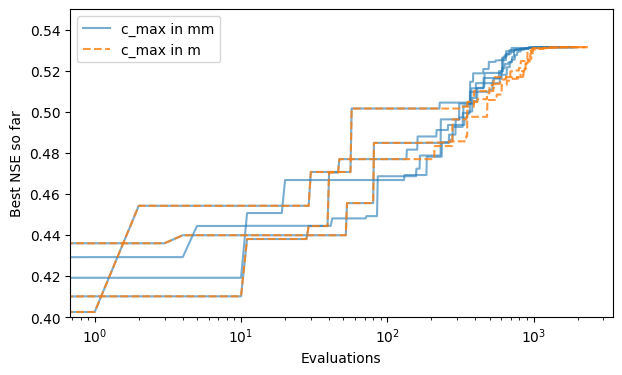

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
for seed, r in runs.items():
    label = "c_max in mm" if seed == 0 else None
    ax.plot(-np.minimum.accumulate(r.funv), color="C0", alpha=0.6, label=label)
for seed, r in runs_m.items():
    label = "c_max in m" if seed == 0 else None
    ax.plot(-np.minimum.accumulate(r.funv), color="C1", ls="--", alpha=0.8, label=label)
ax.set_xscale("log")
ax.set_ylim(0.4, 0.55)
ax.set_xlabel("Evaluations")
ax.set_ylabel("Best NSE so far")
ax.legend()
fig.savefig(Path("images", "reliability.png"), dpi=100, bbox_inches="tight")